# Cronus — Current-Relationship Churn Model

This notebook trains and evaluates the Phase 3 churn model. It uses only the
8,860 current customer-provider relationships in `Dataset/project_dataset.csv`.
Historical relationships are excluded because every non-latest row is churned by
dataset construction. Training on those rows would leak that rule.

The notebook follows one path:

1. Verify the current relationship frame against the Phase 1 contract.
2. Compare logistic regression with a gradient-boosted tree under stratified
   cross-validation.
3. Ablate `relationship_count` and fix the final feature set.
4. Select a decision threshold on out-of-fold training predictions.
5. Evaluate once on a held-out test split.
6. Check calibration, permutation importance, subgroup recall, and a temporal
   split.

All calculations come from the reusable modules in `src/cronus/modeling`. This
notebook adds narrative and plots only. It makes no causal claim and no
production-readiness claim.

## 1. Setup and reproducibility

The notebook reads the canonical CSV through `cronus.validation.validate_csv`.
It needs no database connection and reads no environment secrets.

To run it from a fresh checkout:

```bash
uv sync --group notebook
uv run --group notebook jupyter lab Python/modeling.ipynb
```

The random state is fixed at 42. Every split, search, and bootstrap uses that
seed or a documented derivative of it.

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import precision_recall_curve, roc_curve

from cronus.modeling import (
    CATEGORICAL_FEATURES,
    CURRENT_FEATURES,
    EXCLUDED_FEATURES,
    NUMERIC_FEATURES,
    TARGET_COLUMN,
    bootstrap_intervals,
    calibration_table,
    evaluate_predictions,
    fit_final_model,
    load_current_frame,
    make_xy,
    out_of_fold_probabilities,
    permutation_importance_table,
    predict_churn,
    select_threshold,
    split_current,
    temporal_split,
    threshold_table,
    tune_logistic,
    tune_tree,
)

PALETTE = {
    "retained": "#2A9D8F",
    "churned": "#E76F51",
    "logistic": "#264653",
    "tree": "#E9C46A",
    "muted": "#8D99AE",
    "ink": "#222222",
}
EXPECTED_SHA256 = "a1c3992fcb8da9523aa0f8074f87ce0c2247cac551e3a4fdee02c2690aa2f048"
SELECTED_RECALL_FLOOR = 0.70


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "Dataset" / "project_dataset.csv").exists():
            return candidate
    raise FileNotFoundError("Could not locate Dataset/project_dataset.csv")


PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_PATH = PROJECT_ROOT / "Dataset" / "project_dataset.csv"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 110,
        "figure.figsize": (10, 5),
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "font.family": "DejaVu Sans",
    }
)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 200)


def format_share(value: float) -> str:
    return f"{100 * value:.2f}%"


def format_metric(value: float, interval: tuple[float, float] | None = None) -> str:
    if interval is None:
        return f"{value:.3f}"
    low, high = interval
    return f"{value:.3f} [{low:.3f}, {high:.3f}]"


def parameter_text(params: dict[str, object]) -> str:
    return ", ".join(f"{key.split('__')[-1]}={value}" for key, value in params.items())

## 2. Current-relationship frame

`load_current_frame` validates the CSV and keeps only rows where
`is_latest_relationship` is true. It never deduplicates customers. On this grain
each customer must appear exactly once, so a duplicate is an input error.

The assertions below repeat the Phase 1 and Phase 2 baseline checks. A changed
dataset stops the notebook before any model runs.

In [2]:
file_sha256 = hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest()
assert file_sha256 == EXPECTED_SHA256, "The dataset hash does not match the baseline"

report, current = load_current_frame(DATASET_PATH)
assert report.error_count == 0
assert report.current_relationships == 8_860
assert report.current_churn_count == 847
assert report.historical_relationships == 1_140
assert len(current) == 8_860
assert int(current[TARGET_COLUMN].sum()) == 847
assert current["customer_id"].is_unique
assert current["is_latest_relationship"].all()

snapshot = pd.DataFrame(
    {
        "check": [
            "File SHA-256",
            "Relationships in source",
            "Latest relationships used",
            "Historical rows excluded",
            "Unique customers",
            "Current churn events",
            "Current churn rate",
            "Snapshot date",
            "Registration window",
        ],
        "value": [
            file_sha256[:16] + "...",
            f"{report.row_count:,}",
            f"{len(current):,}",
            f"{report.historical_relationships:,}",
            f"{current['customer_id'].nunique():,}",
            f"{int(current[TARGET_COLUMN].sum()):,}",
            format_share(report.current_churn_rate / 100),
            str(report.as_of_date),
            f"{report.date_min} to {report.date_max}",
        ],
    }
)
display(snapshot)

,check,value
0,File SHA-256,a1c3992fcb8da952...
1,Relationships in source,"10,000"
2,Latest relationships used,"8,860"
3,Historical rows excluded,"1,140"
4,Unique customers,"8,860"
5,Current churn events,847
6,Current churn rate,9.56%
7,Snapshot date,2023-05-04
8,Registration window,2020-01-01 to 2023-05-04


## 3. Feature contract

The target is `churn`: the provider-specific churn flag for the current
relationship. Identifiers, geographic noise, bookkeeping fields, and the
registration date are excluded.

`relationship_count` is a candidate feature, not a fixed part of the contract.
Section 6 tests whether it helps and removes it if the gain is negligible.

In [3]:
feature_rows = [
    ("telecom_partner", "Categorical", "Provider segment"),
    ("gender", "Categorical", "Recorded gender"),
    ("age", "Numeric", "Customer age"),
    ("state", "Categorical", "State of record"),
    ("num_dependents", "Numeric", "Dependents"),
    ("estimated_salary", "Numeric", "Estimated salary"),
    ("calls_made", "Numeric", "Calls made in the observation window"),
    ("sms_sent", "Numeric", "SMS sent in the observation window"),
    ("data_used", "Numeric", "Data used in the observation window"),
    ("tenure_days", "Numeric", "Derived tenure at the snapshot"),
    ("relationship_count", "Numeric", "Candidate, removed after the ablation"),
]
assert tuple(row[0] for row in feature_rows) == CURRENT_FEATURES
assert set(CATEGORICAL_FEATURES) == {"telecom_partner", "gender", "state"}
assert set(NUMERIC_FEATURES) == {
    row[0] for row in feature_rows if row[0] not in CATEGORICAL_FEATURES
}

features_table = pd.DataFrame(feature_rows, columns=["column", "type", "role"])

excluded_rows = [
    ("customer_id", "Identifier; repeats across provider relationships"),
    ("pincode", "Synthetic and unstable across relationships"),
    ("city", "High-cardinality geography"),
    ("record_id", "Database surrogate key"),
    ("dataset_id", "Snapshot key"),
    ("source_row_number", "Source row key"),
    ("is_latest_relationship", "Constant on the current grain"),
    ("relationship_seq", "History position, not a customer attribute"),
    ("date_of_registration", "Used only for the temporal split"),
    ("created_at", "Database insertion timestamp"),
    ("churn", "Target, never a feature"),
]
assert {row[0] for row in excluded_rows} == set(EXCLUDED_FEATURES) | {TARGET_COLUMN}
excluded_table = pd.DataFrame(excluded_rows, columns=["column", "reason"])

display(Markdown("**Model features**"))
display(features_table)
display(Markdown("**Excluded columns**"))
display(excluded_table)

**Model features**

,column,type,role
0,telecom_partner,Categorical,Provider segment
1,gender,Categorical,Recorded gender
2,age,Numeric,Customer age
3,state,Categorical,State of record
4,num_dependents,Numeric,Dependents
5,estimated_salary,Numeric,Estimated salary
6,calls_made,Numeric,Calls made in the observation window
7,sms_sent,Numeric,SMS sent in the observation window
8,data_used,Numeric,Data used in the observation window
9,tenure_days,Numeric,Derived tenure at the snapshot


**Excluded columns**

,column,reason
0,customer_id,Identifier; repeats across provider relationships
1,pincode,Synthetic and unstable across relationships
2,city,High-cardinality geography
3,record_id,Database surrogate key
4,dataset_id,Snapshot key
5,source_row_number,Source row key
6,is_latest_relationship,Constant on the current grain
7,relationship_seq,"History position, not a customer attribute"
8,date_of_registration,Used only for the temporal split
9,created_at,Database insertion timestamp


## 4. Class balance and split

The current base is imbalanced: churn is about one in ten relationships. The
split is stratified on the target, so the training and test frames keep the same
prevalence. The test frame is held out until Section 8.

,split,rows,retained,churned,churn rate
0,Train,"7,088","6,410",678,9.57%
1,Test,"1,772","1,603",169,9.54%


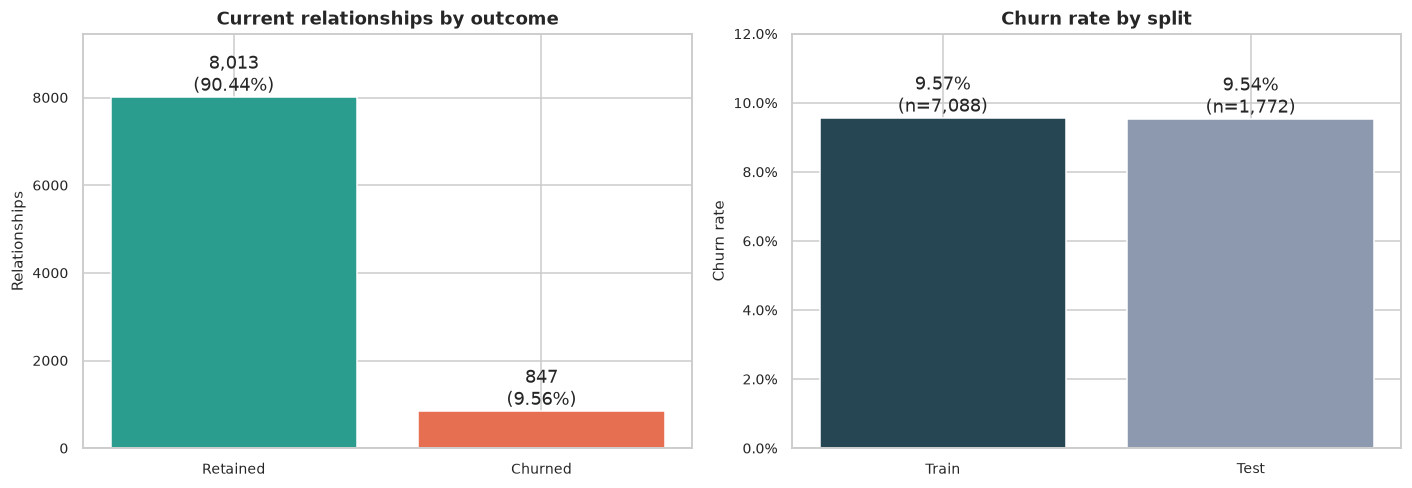

In [4]:
split = split_current(current)
train, test = split.train, split.test
train_features_all, train_target = make_xy(train)
test_features_all, test_target = make_xy(test)
train_features_final, _ = make_xy(train, include_relationship_count=False)
test_features_final, _ = make_xy(test, include_relationship_count=False)

split_table = pd.DataFrame(
    [
        {
            "split": name,
            "rows": f"{len(part):,}",
            "retained": f"{int((part[TARGET_COLUMN] == 0).sum()):,}",
            "churned": f"{int(part[TARGET_COLUMN].sum()):,}",
            "churn rate": format_share(part[TARGET_COLUMN].mean()),
        }
        for name, part in (("Train", train), ("Test", test))
    ]
)
display(split_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
class_counts = current[TARGET_COLUMN].value_counts().reindex([0, 1])
axes[0].bar(
    ["Retained", "Churned"],
    class_counts.to_numpy(),
    color=[PALETTE["retained"], PALETTE["churned"]],
)
for index, value in enumerate(class_counts.to_numpy()):
    axes[0].text(
        index,
        value,
        f"{value:,}\n({format_share(value / len(current))})",
        ha="center",
        va="bottom",
    )
axes[0].set_title("Current relationships by outcome")
axes[0].set_ylabel("Relationships")
axes[0].margins(y=0.18)

split_rates = [train[TARGET_COLUMN].mean(), test[TARGET_COLUMN].mean()]
split_bars = axes[1].bar(
    ["Train", "Test"],
    split_rates,
    color=[PALETTE["logistic"], PALETTE["muted"]],
)
for bar, part in zip(split_bars, (train, test), strict=True):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{format_share(part[TARGET_COLUMN].mean())}\n(n={len(part):,})",
        ha="center",
        va="bottom",
    )
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_ylim(0, 0.12)
axes[1].set_title("Churn rate by split")
axes[1].set_ylabel("Churn rate")
plt.tight_layout()
plt.show()

In [5]:
display(
    Markdown(
        f"The current frame has **{len(current):,}** relationships and "
        f"**{int(current[TARGET_COLUMN].sum()):,}** churn events "
        f"(**{format_share(current[TARGET_COLUMN].mean())}**). "
        f"The stratified split gives **{len(train):,}** training rows and "
        f"**{len(test):,}** test rows. Test prevalence is "
        f"**{format_share(test[TARGET_COLUMN].mean())}**. "
        "The test frame stays untouched until the holdout evaluation."
    )
)

The current frame has **8,860** relationships and **847** churn events (**9.56%**). The stratified split gives **7,088** training rows and **1,772** test rows. Test prevalence is **9.54%**. The test frame stays untouched until the holdout evaluation.

## 5. Cross-validation design

Model selection uses five stratified folds on the training split only. PR-AUC is
the primary metric because the positive class is rare and accuracy is misleading.
ROC-AUC, Brier score, and log loss are secondary checks.

Two candidates use the same preprocessing contract:

- **Logistic regression** with L2 regularisation, scaled numeric features, and
  one-hot encoded categorical features.
- **Gradient-boosted tree** with unscaled features.

Rare states are grouped by `OneHotEncoder(min_frequency=50)`. Unseen categories
are ignored. All fitting happens inside the pipeline, so no preprocessing sees
the test fold.

The searches are bounded. The logistic grid has 8 combinations and the tree
search has 20 draws. The printed CV scores are slightly optimistic because the
search and the report use the same folds.

In [6]:
logistic_full = tune_logistic(train_features_all, train_target, include_relationship_count=True)
tree_full = tune_tree(train_features_all, train_target, include_relationship_count=True)

cv_table = pd.DataFrame(
    [
        {
            "model": "Logistic regression",
            "features": len(train_features_all.columns),
            "best parameters": parameter_text(logistic_full.best_params),
            "PR-AUC": f"{logistic_full.cv.pr_auc_mean:.4f} ± {logistic_full.cv.pr_auc_std:.4f}",
            "ROC-AUC": f"{logistic_full.cv.roc_auc_mean:.4f}",
            "Brier": f"{logistic_full.cv.brier_mean:.4f}",
            "log loss": f"{logistic_full.cv.log_loss_mean:.4f}",
        },
        {
            "model": "Gradient-boosted tree",
            "features": len(train_features_all.columns),
            "best parameters": parameter_text(tree_full.best_params),
            "PR-AUC": f"{tree_full.cv.pr_auc_mean:.4f} ± {tree_full.cv.pr_auc_std:.4f}",
            "ROC-AUC": f"{tree_full.cv.roc_auc_mean:.4f}",
            "Brier": f"{tree_full.cv.brier_mean:.4f}",
            "log loss": f"{tree_full.cv.log_loss_mean:.4f}",
        },
    ]
)
display(cv_table)

,model,features,best parameters,PR-AUC,ROC-AUC,Brier,log loss
0,Logistic regression,11,"C=0.1, class_weight=None",0.2676 ± 0.0532,0.7499,0.0794,0.2786
1,Gradient-boosted tree,11,"min_samples_leaf=20, max_leaf_nodes=15, learning_rate=0.03, l2_regularization=0.0",0.2400 ± 0.0475,0.7362,0.0810,0.2848


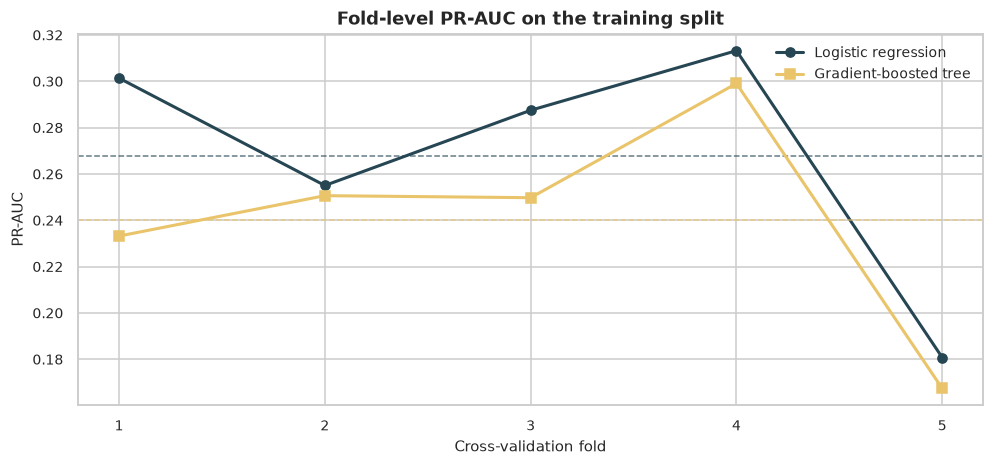

In [7]:
fig, ax = plt.subplots(figsize=(9.2, 4.4))
for model, label, color, marker in (
    (logistic_full, "Logistic regression", PALETTE["logistic"], "o"),
    (tree_full, "Gradient-boosted tree", PALETTE["tree"], "s"),
):
    folds = model.cv.fold_scores
    ax.plot(
        folds["fold"],
        folds["pr_auc"],
        marker=marker,
        color=color,
        linewidth=2,
        label=label,
    )
    ax.axhline(model.cv.pr_auc_mean, color=color, linestyle="--", linewidth=1, alpha=0.7)
ax.set_xticks(range(1, 6))
ax.set_xlabel("Cross-validation fold")
ax.set_ylabel("PR-AUC")
ax.set_title("Fold-level PR-AUC on the training split")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [8]:
pr_gap = logistic_full.cv.pr_auc_mean - tree_full.cv.pr_auc_mean
brier_gap = tree_full.cv.brier_mean - logistic_full.cv.brier_mean
display(
    Markdown(
        f"Logistic regression reaches a CV PR-AUC of "
        f"**{logistic_full.cv.pr_auc_mean:.4f} ± {logistic_full.cv.pr_auc_std:.4f}**, "
        f"which is **{pr_gap:.4f}** above the tree. It also has the lower Brier "
        f"score by **{brier_gap:.4f}**. The tree does not improve ranking or "
        "probability quality on this sample, so the notebook keeps the simpler "
        "logistic model."
    )
)

Logistic regression reaches a CV PR-AUC of **0.2676 ± 0.0532**, which is **0.0276** above the tree. It also has the lower Brier score by **0.0016**. The tree does not improve ranking or probability quality on this sample, so the notebook keeps the simpler logistic model.

## 6. Ablation: `relationship_count`

`relationship_count` describes how many provider relationships a customer has.
It may carry loyalty or shopping behaviour, but it also risks acting as a proxy
for the historical construction. The ablation tunes the same logistic pipeline
with and without it on the training split. The smaller model wins unless the
drop in CV PR-AUC is material.

In [9]:
logistic_no_rc = tune_logistic(train_features_all, train_target, include_relationship_count=False)

ablation_table = pd.DataFrame(
    [
        {
            "feature set": "With relationship_count",
            "features": len(train_features_all.columns),
            "PR-AUC": f"{logistic_full.cv.pr_auc_mean:.4f} ± {logistic_full.cv.pr_auc_std:.4f}",
            "ROC-AUC": f"{logistic_full.cv.roc_auc_mean:.4f}",
            "Brier": f"{logistic_full.cv.brier_mean:.4f}",
        },
        {
            "feature set": "Without relationship_count",
            "features": len(train_features_final.columns),
            "PR-AUC": f"{logistic_no_rc.cv.pr_auc_mean:.4f} ± {logistic_no_rc.cv.pr_auc_std:.4f}",
            "ROC-AUC": f"{logistic_no_rc.cv.roc_auc_mean:.4f}",
            "Brier": f"{logistic_no_rc.cv.brier_mean:.4f}",
        },
    ]
)
display(ablation_table)

,feature set,features,PR-AUC,ROC-AUC,Brier
0,With relationship_count,11,0.2676 ± 0.0532,0.7499,0.0794
1,Without relationship_count,10,0.2662 ± 0.0493,0.7497,0.0794


In [10]:
ablation_delta = logistic_no_rc.cv.pr_auc_mean - logistic_full.cv.pr_auc_mean
display(
    Markdown(
        f"Dropping `relationship_count` changes CV PR-AUC by "
        f"**{ablation_delta:+.4f}**. The change is small relative to the fold "
        f"standard deviation of **{logistic_full.cv.pr_auc_std:.4f}**. The final "
        "model uses the 10-feature contract without it. This keeps the feature "
        "set focused on current customer attributes and usage."
    )
)

Dropping `relationship_count` changes CV PR-AUC by **-0.0014**. The change is small relative to the fold standard deviation of **0.0532**. The final model uses the 10-feature contract without it. This keeps the feature set focused on current customer attributes and usage.

## 7. Threshold policy

The default 0.5 threshold is not usable here. The model is trained on a 9.6%
positive base, and its probabilities rarely exceed 0.5. The notebook selects a
threshold on **out-of-fold training predictions**, never on the test split.

Two policies are reported:

- **Max-F1:** the threshold with the highest F1 on out-of-fold predictions.
- **70% recall floor:** the highest threshold that reaches at least 70% recall,
  for a team that prefers to contact more customers.

The chosen threshold is a business decision, not a property of the model.

,policy,threshold,precision,recall,F1,predicted positives
0,0.50 default,0.5000,0.643,0.013,0.026,14
1,Max-F1 (selected),0.1840,0.270,0.385,0.317,968
2,70% recall floor,0.0981,0.182,0.701,0.288,"2,617"


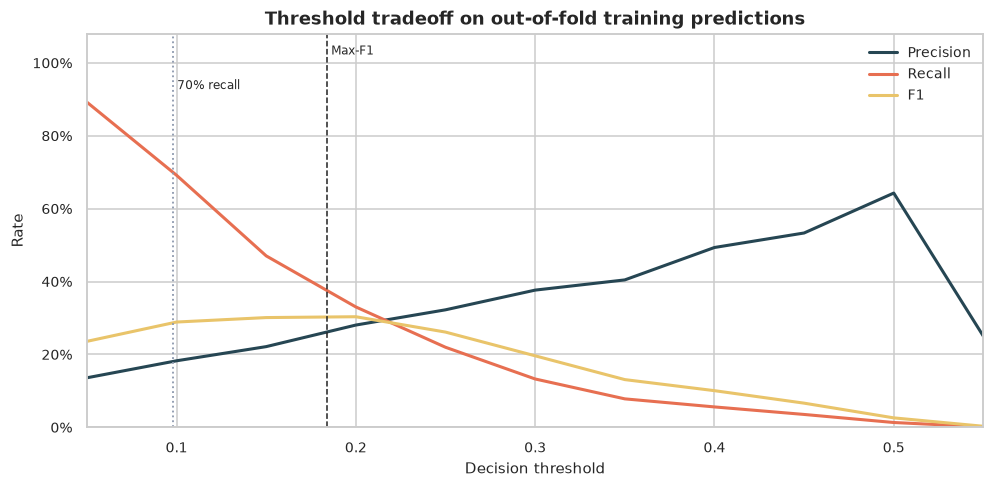

In [11]:
oof_probability = out_of_fold_probabilities(
    logistic_no_rc.estimator,
    train_features_final,
    train_target,
)
max_f1_threshold = select_threshold(train_target, oof_probability)
recall70_threshold = select_threshold(
    train_target,
    oof_probability,
    min_recall=SELECTED_RECALL_FLOOR,
)
assert 0 < max_f1_threshold < 1
assert 0 < recall70_threshold < 1

threshold_rows = []
for label, threshold in (
    ("0.50 default", 0.5),
    ("Max-F1 (selected)", max_f1_threshold),
    ("70% recall floor", recall70_threshold),
):
    summary = evaluate_predictions(train_target, oof_probability, threshold=threshold)
    threshold_rows.append(
        {
            "policy": label,
            "threshold": f"{threshold:.4f}",
            "precision": f"{summary.precision:.3f}",
            "recall": f"{summary.recall:.3f}",
            "F1": f"{summary.f1:.3f}",
            "predicted positives": f"{summary.true_positive + summary.false_positive:,}",
        }
    )
display(pd.DataFrame(threshold_rows))

tradeoff = threshold_table(train_target, oof_probability)
fig, ax = plt.subplots(figsize=(9.2, 4.6))
ax.plot(
    tradeoff["threshold"],
    tradeoff["precision"],
    color=PALETTE["logistic"],
    linewidth=2,
    label="Precision",
)
ax.plot(
    tradeoff["threshold"], tradeoff["recall"], color=PALETTE["churned"], linewidth=2, label="Recall"
)
ax.plot(tradeoff["threshold"], tradeoff["f1"], color=PALETTE["tree"], linewidth=2, label="F1")
ax.axvline(max_f1_threshold, color=PALETTE["ink"], linestyle="--", linewidth=1)
ax.text(max_f1_threshold, 1.015, " Max-F1", va="bottom", fontsize=8)
ax.axvline(recall70_threshold, color=PALETTE["muted"], linestyle=":", linewidth=1.2)
ax.text(recall70_threshold, 0.92, " 70% recall", va="bottom", fontsize=8)
ax.set_xlim(0.05, 0.55)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Rate")
ax.set_title("Threshold tradeoff on out-of-fold training predictions")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [12]:
max_f1_oof = evaluate_predictions(train_target, oof_probability, threshold=max_f1_threshold)
recall70_oof = evaluate_predictions(train_target, oof_probability, threshold=recall70_threshold)
display(
    Markdown(
        f"Max-F1 selects **{max_f1_threshold:.4f}** on out-of-fold predictions. "
        f"At that threshold the training estimate is "
        f"**{max_f1_oof.precision:.3f} precision** and "
        f"**{max_f1_oof.recall:.3f} recall** (F1 **{max_f1_oof.f1:.3f}**). "
        f"The 70% recall policy selects **{recall70_threshold:.4f}** and reaches "
        f"**{recall70_oof.recall:.3f} recall** with "
        f"**{recall70_oof.precision:.3f} precision**. The selected policy is "
        "max-F1, and the 70% alternative is reported for capacity planning."
    )
)

Max-F1 selects **0.1840** on out-of-fold predictions. At that threshold the training estimate is **0.270 precision** and **0.385 recall** (F1 **0.317**). The 70% recall policy selects **0.0981** and reaches **0.701 recall** with **0.182 precision**. The selected policy is max-F1, and the 70% alternative is reported for capacity planning.

## 8. Holdout evaluation

The test split is now evaluated once. The model and threshold are already fixed,
so this section does not tune anything. Point estimates come with stratified
bootstrap 95% intervals over 1,000 resamples.

In [13]:
holdout_probability = logistic_no_rc.estimator.predict_proba(test_features_final)[:, 1]
intervals = bootstrap_intervals(
    test_target,
    holdout_probability,
    threshold=max_f1_threshold,
    n_resamples=1_000,
)

holdout_rows = []
for label, threshold in (
    ("0.50 default", 0.5),
    ("Max-F1 (selected)", max_f1_threshold),
    ("70% recall floor", recall70_threshold),
):
    summary = evaluate_predictions(test_target, holdout_probability, threshold=threshold)
    holdout_rows.append(
        {
            "policy": label,
            "threshold": f"{threshold:.4f}",
            "precision": f"{summary.precision:.3f}",
            "recall": f"{summary.recall:.3f}",
            "F1": f"{summary.f1:.3f}",
            "predicted positives": f"{summary.true_positive + summary.false_positive:,}",
            "true positives": f"{summary.true_positive:,}",
            "false positives": f"{summary.false_positive:,}",
            "false negatives": f"{summary.false_negative:,}",
        }
    )
display(pd.DataFrame(holdout_rows))

holdout_summary = evaluate_predictions(
    test_target,
    holdout_probability,
    threshold=max_f1_threshold,
)
metric_rows = [
    ("PR-AUC", holdout_summary.pr_auc, intervals["pr_auc"]),
    ("ROC-AUC", holdout_summary.roc_auc, intervals["roc_auc"]),
    ("Brier", holdout_summary.brier, intervals["brier"]),
    ("Precision", holdout_summary.precision, intervals["precision"]),
    ("Recall", holdout_summary.recall, intervals["recall"]),
    ("F1", holdout_summary.f1, intervals["f1"]),
]
display(
    pd.DataFrame(
        [
            {"metric": name, "estimate [95% CI]": format_metric(value, interval)}
            for name, value, interval in metric_rows
        ]
    )
)

,policy,threshold,precision,recall,F1,predicted positives,true positives,false positives,false negatives
0,0.50 default,0.5000,0.500,0.012,0.023,4,2,2,167
1,Max-F1 (selected),0.1840,0.241,0.337,0.281,237,57,180,112
2,70% recall floor,0.0981,0.172,0.669,0.273,658,113,545,56


,metric,estimate [95% CI]
0,PR-AUC,"0.231 [0.191, 0.293]"
1,ROC-AUC,"0.729 [0.688, 0.765]"
2,Brier,"0.081 [0.078, 0.083]"
3,Precision,"0.241 [0.193, 0.288]"
4,Recall,"0.337 [0.266, 0.408]"
5,F1,"0.281 [0.224, 0.335]"


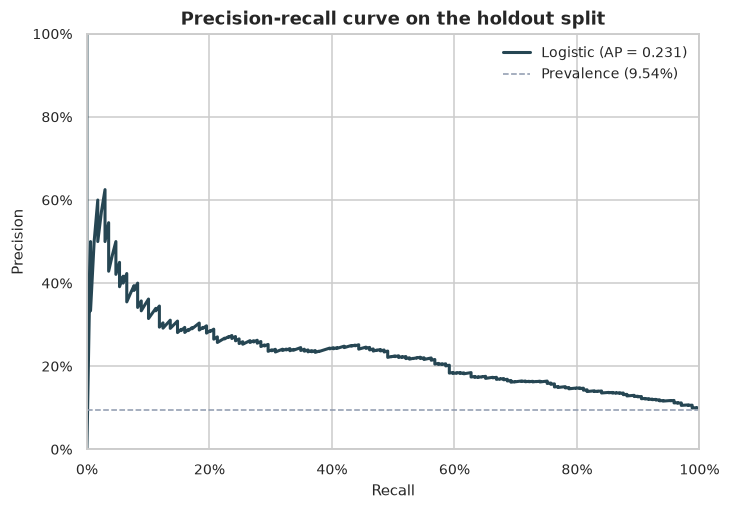

In [14]:
precision, recall, _ = precision_recall_curve(test_target, holdout_probability)
fig, ax = plt.subplots(figsize=(6.8, 4.8))
ax.plot(
    recall,
    precision,
    color=PALETTE["logistic"],
    linewidth=2,
    label=f"Logistic (AP = {holdout_summary.pr_auc:.3f})",
)
ax.axhline(
    test_target.mean(),
    color=PALETTE["muted"],
    linestyle="--",
    linewidth=1,
    label=f"Prevalence ({format_share(test_target.mean())})",
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curve on the holdout split")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

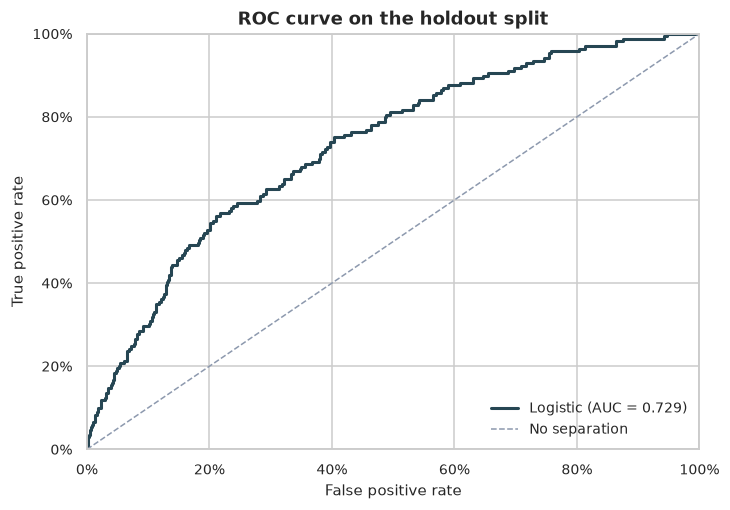

In [15]:
false_positive_rate, true_positive_rate, _ = roc_curve(test_target, holdout_probability)
fig, ax = plt.subplots(figsize=(6.8, 4.8))
ax.plot(
    false_positive_rate,
    true_positive_rate,
    color=PALETTE["logistic"],
    linewidth=2,
    label=f"Logistic (AUC = {holdout_summary.roc_auc:.3f})",
)
ax.plot([0, 1], [0, 1], color=PALETTE["muted"], linestyle="--", linewidth=1, label="No separation")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve on the holdout split")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

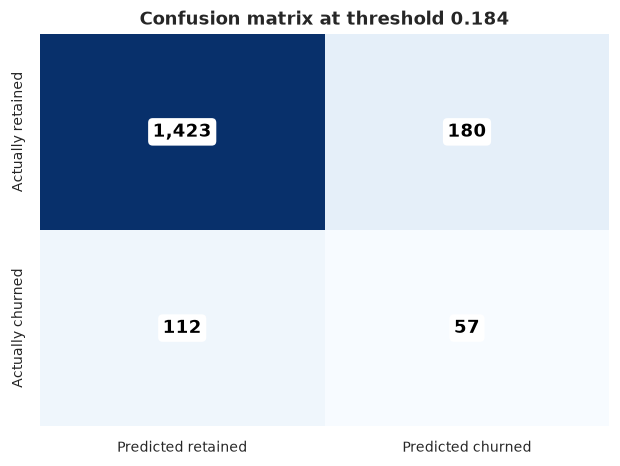

In [16]:
confusion = np.array(
    [
        [holdout_summary.true_negative, holdout_summary.false_positive],
        [holdout_summary.false_negative, holdout_summary.true_positive],
    ]
)
fig, ax = plt.subplots(figsize=(5.8, 4.4))
sns.heatmap(
    confusion,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted retained", "Predicted churned"],
    yticklabels=["Actually retained", "Actually churned"],
    annot_kws={
        "fontsize": 12,
        "fontweight": "bold",
        "color": "black",
        "bbox": {
            "boxstyle": "round,pad=0.25",
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 1.0,
        },
    },
    ax=ax,
)
ax.set_title(f"Confusion matrix at threshold {max_f1_threshold:.3f}")
plt.tight_layout()
plt.show()

In [17]:
display(
    Markdown(
        f"On the holdout split, PR-AUC is **{format_metric(holdout_summary.pr_auc, intervals['pr_auc'])}** "
        f"and ROC-AUC is **{format_metric(holdout_summary.roc_auc, intervals['roc_auc'])}**. "
        f"Brier score is **{format_metric(holdout_summary.brier, intervals['brier'])}**. "
        f"At the selected threshold of **{max_f1_threshold:.4f}**, the model flags "
        f"**{holdout_summary.true_positive + holdout_summary.false_positive:,}** "
        f"relationships, catches **{holdout_summary.true_positive}** of "
        f"**{holdout_summary.true_positive + holdout_summary.false_negative}** churners, "
        f"and raises **{holdout_summary.false_positive}** false alarms. "
        f"Precision is **{holdout_summary.precision:.3f}** and recall is "
        f"**{holdout_summary.recall:.3f}**. The default 0.5 threshold catches "
        f"only **{evaluate_predictions(test_target, holdout_probability, threshold=0.5).true_positive}** "
        "churners, which confirms that the threshold must travel with the model."
    )
)

On the holdout split, PR-AUC is **0.231 [0.191, 0.293]** and ROC-AUC is **0.729 [0.688, 0.765]**. Brier score is **0.081 [0.078, 0.083]**. At the selected threshold of **0.1840**, the model flags **237** relationships, catches **57** of **169** churners, and raises **180** false alarms. Precision is **0.241** and recall is **0.337**. The default 0.5 threshold catches only **2** churners, which confirms that the threshold must travel with the model.

## 9. Calibration

Ranking metrics can look acceptable while the probabilities remain biased. The
calibration table bins holdout predictions by quantile and compares the mean
predicted probability with the observed churn rate in each bin.

A well-calibrated model sits near the diagonal. The Brier score summarises the
same question with one number.

,n,mean_predicted,observed_rate,gap
0,178,0.008,0.011,0.003
1,177,0.022,0.028,0.006
2,177,0.034,0.051,0.017
3,177,0.047,0.045,-0.002
4,177,0.063,0.073,0.011
5,177,0.081,0.085,0.003
6,177,0.103,0.096,-0.007
7,177,0.132,0.096,-0.036
8,177,0.177,0.209,0.032
9,178,0.290,0.258,-0.032


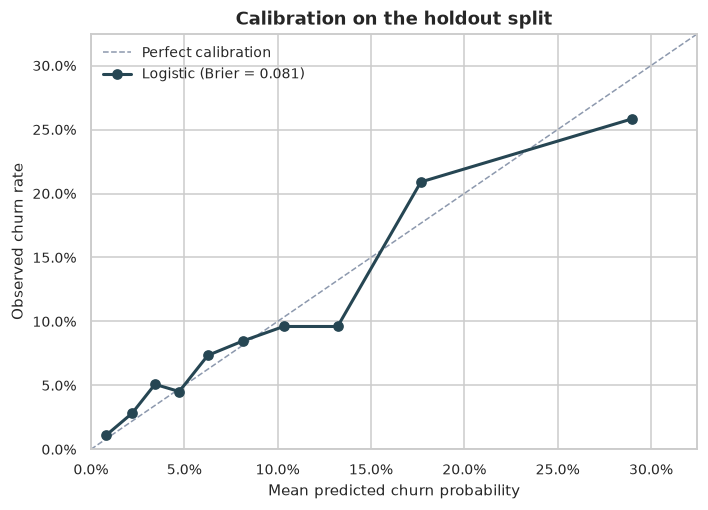

In [18]:
calibration = calibration_table(test_target, holdout_probability, bins=10)
display(calibration.drop(columns=["bin"]).round(3))

upper = max(calibration["mean_predicted"].max(), calibration["observed_rate"].max()) * 1.12
fig, ax = plt.subplots(figsize=(6.6, 4.8))
ax.plot(
    [0, upper],
    [0, upper],
    color=PALETTE["muted"],
    linestyle="--",
    linewidth=1,
    label="Perfect calibration",
)
ax.plot(
    calibration["mean_predicted"],
    calibration["observed_rate"],
    marker="o",
    color=PALETTE["logistic"],
    linewidth=2,
    label=f"Logistic (Brier = {holdout_summary.brier:.3f})",
)
ax.set_xlim(0, upper)
ax.set_ylim(0, upper)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Mean predicted churn probability")
ax.set_ylabel("Observed churn rate")
ax.set_title("Calibration on the holdout split")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

In [19]:
largest_gap = calibration.loc[calibration["gap"].abs().idxmax()]
display(
    Markdown(
        f"The largest calibration gap is **{largest_gap['gap']:+.3f}** in the bin "
        f"with **{int(largest_gap['n']):,}** relationships, where the mean "
        f"prediction is **{largest_gap['mean_predicted']:.3f}** and the observed "
        f"rate is **{largest_gap['observed_rate']:.3f}**. The curve stays close "
        "to the diagonal, but the small positive base makes bin-level gaps noisy. "
        "Treat the probabilities as ordinal risk scores for prioritisation, not "
        "as exact churn rates for an individual customer."
    )
)

The largest calibration gap is **-0.036** in the bin with **177** relationships, where the mean prediction is **0.132** and the observed rate is **0.096**. The curve stays close to the diagonal, but the small positive base makes bin-level gaps noisy. Treat the probabilities as ordinal risk scores for prioritisation, not as exact churn rates for an individual customer.

## 10. What drives the model

Permutation importance measures how much holdout PR-AUC drops when one feature
is shuffled. It describes the fitted model and the data, not a causal effect. A
high value means the model uses the feature, not that the feature causes churn.

Correlated usage features share credit, so their individual values are a lower
bound on the group contribution.

,feature,importance_mean,importance_std
0,telecom_partner,0.0434,0.0090
1,data_used,0.0320,0.0168
2,calls_made,0.0231,0.0077
3,tenure_days,0.0178,0.0095
4,estimated_salary,0.0119,0.0072
5,num_dependents,0.0118,0.0082
6,sms_sent,0.0020,0.0057
7,gender,-0.0002,0.0007
8,age,-0.0005,0.0003
9,state,-0.0007,0.0049


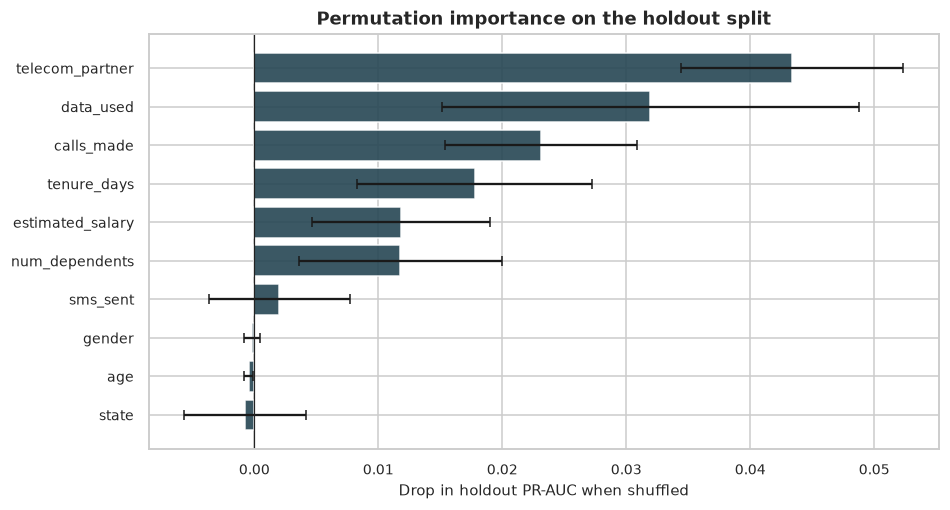

In [20]:
importance = permutation_importance_table(
    logistic_no_rc.estimator,
    test_features_final,
    test_target,
    n_repeats=10,
)
display(importance.round(4))

ordered = importance.sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(8.8, 4.8))
ax.barh(
    ordered["feature"],
    ordered["importance_mean"],
    xerr=ordered["importance_std"],
    color=PALETTE["logistic"],
    alpha=0.9,
    capsize=3,
)
ax.axvline(0, color=PALETTE["ink"], linewidth=0.8)
ax.set_xlabel("Drop in holdout PR-AUC when shuffled")
ax.set_title("Permutation importance on the holdout split")
plt.tight_layout()
plt.show()

In [21]:
top_features = importance.head(4)
feature_text = ", ".join(
    f"`{row.feature}` ({row.importance_mean:.4f})" for row in top_features.itertuples()
)
display(
    Markdown(
        f"The four most used features are {feature_text}. Provider, data usage, "
        "calls, and tenure carry most of the signal. The model still has a wide "
        "gap to perfect ranking, so these associations are modest."
    )
)

The four most used features are `telecom_partner` (0.0434), `data_used` (0.0320), `calls_made` (0.0231), `tenure_days` (0.0178). Provider, data usage, calls, and tenure carry most of the signal. The model still has a wide gap to perfect ranking, so these associations are modest.

## 11. Subgroup recall

An aggregate recall can hide weak performance in a segment. This section reports
recall at the selected threshold for provider, tenure band, age band, and calls
quartile on the holdout split. Calls quartiles use the training split edges.

Small segments have wide uncertainty. A low recall in a segment with few
positives is a warning to inspect, not proof of unfair behaviour.

,segment,n,positives,recall,precision
1,BSNL,320,52,0.577,0.291
0,Airtel,503,40,0.375,0.197
3,Vodafone,445,45,0.178,0.216
2,Reliance Jio,504,32,0.125,0.190


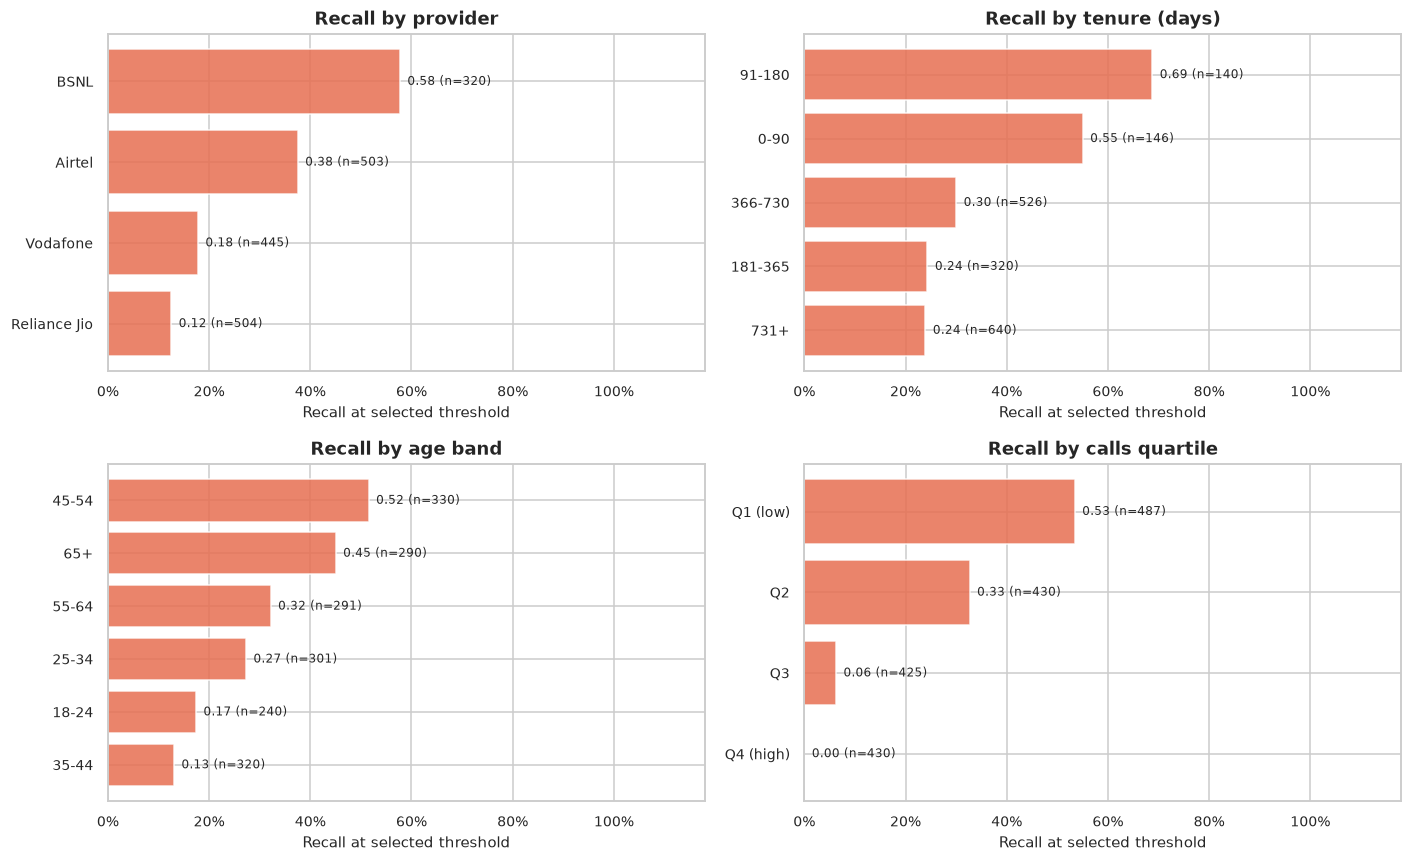

In [22]:
subgroup_frame = test.assign(
    probability=holdout_probability,
    predicted=(holdout_probability >= max_f1_threshold).astype(int),
)
subgroup_frame["tenure_band"] = pd.cut(
    subgroup_frame["tenure_days"],
    bins=[-1, 90, 180, 365, 730, 10_000],
    labels=["0-90", "91-180", "181-365", "366-730", "731+"],
)
subgroup_frame["age_band"] = pd.cut(
    subgroup_frame["age"],
    bins=[17, 24, 34, 44, 54, 64, 100],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"],
)
usage_edges = train["calls_made"].quantile([0, 0.25, 0.5, 0.75, 1.0]).to_numpy(copy=True)
usage_edges[0] = -np.inf
usage_edges[-1] = np.inf
subgroup_frame["usage_band"] = pd.cut(
    subgroup_frame["calls_made"],
    bins=usage_edges,
    labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"],
    include_lowest=True,
)


def subgroup_summary(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    rows = []
    for key, group in frame.groupby(column, observed=True):
        positives = int(group[TARGET_COLUMN].sum())
        true_positive = int(((group[TARGET_COLUMN] == 1) & (group["predicted"] == 1)).sum())
        false_positive = int(((group[TARGET_COLUMN] == 0) & (group["predicted"] == 1)).sum())
        rows.append(
            {
                "segment": str(key),
                "n": len(group),
                "positives": positives,
                "recall": true_positive / positives if positives else np.nan,
                "precision": (
                    true_positive / (true_positive + false_positive)
                    if true_positive + false_positive
                    else np.nan
                ),
            }
        )
    return pd.DataFrame(rows)


provider_table = subgroup_summary(subgroup_frame, "telecom_partner").sort_values(
    "recall",
    ascending=False,
)
display(provider_table.round(3))

dimensions = [
    ("telecom_partner", "Provider"),
    ("tenure_band", "Tenure (days)"),
    ("age_band", "Age band"),
    ("usage_band", "Calls quartile"),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (column, title) in zip(axes.ravel(), dimensions, strict=True):
    table = subgroup_summary(subgroup_frame, column).sort_values("recall")
    positions = np.arange(len(table))
    ax.barh(positions, table["recall"], color=PALETTE["churned"], alpha=0.85)
    ax.set_yticks(positions, table["segment"])
    for position, row in zip(positions, table.itertuples(), strict=True):
        share = "n/a" if np.isnan(row.recall) else f"{row.recall:.2f}"
        ax.text(
            (0 if np.isnan(row.recall) else row.recall) + 0.015,
            position,
            f"{share} (n={row.n:,})",
            va="center",
            fontsize=8,
        )
    ax.set_xlim(0, 1.18)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"Recall by {title.lower()}")
    ax.set_xlabel("Recall at selected threshold")
plt.tight_layout()
plt.show()

In [23]:
provider_recall = provider_table.set_index("segment")["recall"]
usage_recall = subgroup_summary(subgroup_frame, "usage_band").set_index("segment")["recall"]
display(
    Markdown(
        f"Provider recall ranges from **{provider_recall.min():.3f}** to "
        f"**{provider_recall.max():.3f}**. The highest-recall provider has "
        f"**{int(provider_table.iloc[0]['positives'])}** holdout positives, while "
        f"the lowest has **{int(provider_table.iloc[-1]['positives'])}**. "
        f"The highest calls quartile has recall "
        f"**{usage_recall.loc['Q4 (high)']:.3f}**, so the model under-flags "
        "churners who use the service heavily. The gaps are large enough to "
        "monitor in Phase 4, but the small segment counts limit what this holdout "
        "can prove. Usage and tenure bands show the same pattern: the model is "
        "stronger in some regions of the input space than in others."
    )
)

Provider recall ranges from **0.125** to **0.577**. The highest-recall provider has **52** holdout positives, while the lowest has **32**. The highest calls quartile has recall **0.000**, so the model under-flags churners who use the service heavily. The gaps are large enough to monitor in Phase 4, but the small segment counts limit what this holdout can prove. Usage and tenure bands show the same pattern: the model is stronger in some regions of the input space than in others.

## 12. Temporal check

A random split answers whether the model generalises to similar relationships.
A temporal split asks a harder question: does a model trained on older
registrations rank newer ones?

The temporal check trains on 2020–2021 registrations and tests on 2022–2023.
The latest rows have shorter tenure at the snapshot, so the test prevalence is
higher. The model is tuned and thresholded on the older period only. This is a
diagnostic, not a second model-selection loop.

In [24]:
time_split = temporal_split(current)
time_train, time_test = time_split.train, time_split.test
time_train_features, time_train_target = make_xy(
    time_train,
    include_relationship_count=False,
)
time_test_features, time_test_target = make_xy(
    time_test,
    include_relationship_count=False,
)

time_model = tune_logistic(
    time_train_features,
    time_train_target,
    include_relationship_count=False,
)
time_oof = out_of_fold_probabilities(
    time_model.estimator,
    time_train_features,
    time_train_target,
)
time_threshold = select_threshold(time_train_target, time_oof)
time_probability = time_model.estimator.predict_proba(time_test_features)[:, 1]
time_summary = evaluate_predictions(
    time_test_target,
    time_probability,
    threshold=time_threshold,
)

time_split_table = pd.DataFrame(
    [
        {
            "period": "Train 2020-2021",
            "rows": f"{len(time_train):,}",
            "churned": f"{int(time_train_target.sum()):,}",
            "churn rate": format_share(time_train_target.mean()),
        },
        {
            "period": "Test 2022-2023",
            "rows": f"{len(time_test):,}",
            "churned": f"{int(time_test_target.sum()):,}",
            "churn rate": format_share(time_test_target.mean()),
        },
    ]
)
display(time_split_table)
display(
    pd.DataFrame(
        [
            {
                "check": "CV PR-AUC on older period",
                "value": f"{time_model.cv.pr_auc_mean:.4f} ± {time_model.cv.pr_auc_std:.4f}",
            },
            {"check": "Selected threshold", "value": f"{time_threshold:.4f}"},
            {"check": "Test PR-AUC", "value": f"{time_summary.pr_auc:.4f}"},
            {"check": "Test ROC-AUC", "value": f"{time_summary.roc_auc:.4f}"},
            {"check": "Test Brier", "value": f"{time_summary.brier:.4f}"},
            {"check": "Test precision", "value": f"{time_summary.precision:.4f}"},
            {"check": "Test recall", "value": f"{time_summary.recall:.4f}"},
            {"check": "Test F1", "value": f"{time_summary.f1:.4f}"},
        ]
    )
)

,period,rows,churned,churn rate
0,Train 2020-2021,"4,861",385,7.92%
1,Test 2022-2023,"3,999",462,11.55%


,check,value
0,CV PR-AUC on older period,0.2303 ± 0.0383
1,Selected threshold,0.1410
2,Test PR-AUC,0.2776
3,Test ROC-AUC,0.7450
4,Test Brier,0.0941
5,Test precision,0.2265
6,Test recall,0.6212
7,Test F1,0.3320


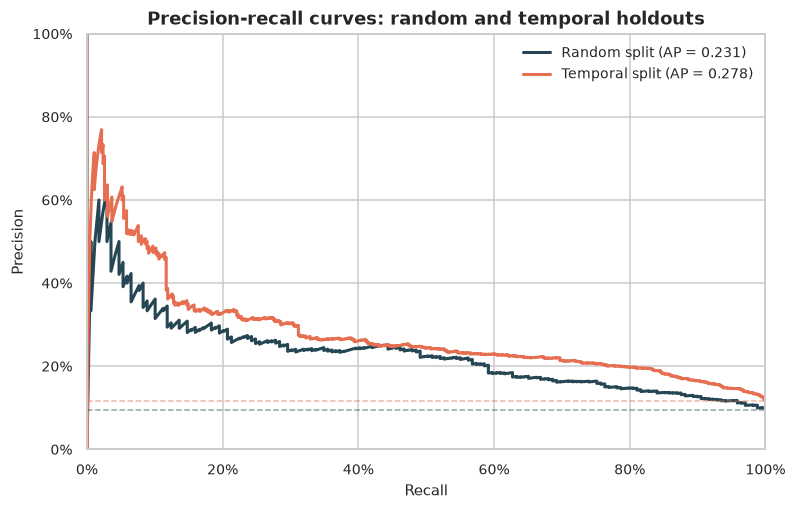

In [25]:
random_precision, random_recall, _ = precision_recall_curve(test_target, holdout_probability)
time_precision, time_recall, _ = precision_recall_curve(time_test_target, time_probability)
fig, ax = plt.subplots(figsize=(7.4, 4.8))
ax.plot(
    random_recall,
    random_precision,
    color=PALETTE["logistic"],
    linewidth=2,
    label=f"Random split (AP = {holdout_summary.pr_auc:.3f})",
)
ax.plot(
    time_recall,
    time_precision,
    color=PALETTE["churned"],
    linewidth=2,
    label=f"Temporal split (AP = {time_summary.pr_auc:.3f})",
)
ax.axhline(test_target.mean(), color=PALETTE["logistic"], linestyle="--", linewidth=1, alpha=0.5)
ax.axhline(
    time_test_target.mean(), color=PALETTE["churned"], linestyle="--", linewidth=1, alpha=0.5
)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves: random and temporal holdouts")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

In [26]:
display(
    Markdown(
        f"The temporal test has **{format_share(time_test_target.mean())}** churn, "
        f"higher than the random test set at **{format_share(test_target.mean())}**. "
        f"PR-AUC is **{time_summary.pr_auc:.4f}** and ROC-AUC is "
        f"**{time_summary.roc_auc:.4f}**. Brier score rises to "
        f"**{time_summary.brier:.4f}**, so probability quality is worse even "
        "though ranking remains similar. The max-F1 threshold also shifts, which "
        "shows that a threshold calibrated on one period does not transfer "
        "automatically. Phase 4 must recalibrate when the active dataset changes."
    )
)

The temporal test has **11.55%** churn, higher than the random test set at **9.54%**. PR-AUC is **0.2776** and ROC-AUC is **0.7450**. Brier score rises to **0.0941**, so probability quality is worse even though ranking remains similar. The max-F1 threshold also shifts, which shows that a threshold calibrated on one period does not transfer automatically. Phase 4 must recalibrate when the active dataset changes.

## 13. Final fit and Phase 4 handoff

The final step refits the selected pipeline on all 8,860 current relationships,
using the selected hyperparameters and threshold. This fitted object is the
reusable model for Phase 4.

No model artifact is committed. Phase 4 imports the same functions, fits on the
active dataset, and caches the pipeline in the Streamlit process. The Streamlit
upload flow and the prediction interface stay out of scope for Phase 3.

In [27]:
final_model = fit_final_model(
    current,
    model_name="logistic",
    include_relationship_count=False,
    params=logistic_no_rc.best_params,
    threshold=max_f1_threshold,
)
current_probability = predict_churn(final_model, current)
assert len(current_probability) == len(current)
assert np.isfinite(current_probability).all()
assert ((current_probability >= 0) & (current_probability <= 1)).all()

model_card = pd.DataFrame(
    {
        "item": [
            "Model",
            "Features",
            "Training rows",
            "Training churn events",
            "Selected threshold",
            "Holdout PR-AUC",
            "Holdout ROC-AUC",
            "Holdout Brier",
            "Scikit-learn version",
        ],
        "value": [
            "Logistic regression with L2 penalty",
            f"{len(final_model.features)}: {', '.join(final_model.features)}",
            f"{len(current):,}",
            f"{int(current[TARGET_COLUMN].sum()):,}",
            f"{max_f1_threshold:.4f}",
            f"{holdout_summary.pr_auc:.4f}",
            f"{holdout_summary.roc_auc:.4f}",
            f"{holdout_summary.brier:.4f}",
            sklearn.__version__,
        ],
    }
)
display(model_card)

preview = pd.DataFrame(
    {
        "customer_id": current["customer_id"].head(8),
        "telecom_partner": current["telecom_partner"].head(8),
        "tenure_days": current["tenure_days"].head(8),
        "churn_probability": np.round(current_probability[:8], 4),
        "above_threshold": current_probability[:8] >= max_f1_threshold,
    }
)
display(preview)

,item,value
0,Model,Logistic regression with L2 penalty
1,Features,"10: telecom_partner, gender, age, state, num_dependents, estimated_salary, calls_made, sms_sent, data_used, tenure_days"
2,Training rows,"8,860"
3,Training churn events,847
4,Selected threshold,0.1840
5,Holdout PR-AUC,0.2312
6,Holdout ROC-AUC,0.7295
7,Holdout Brier,0.0806
8,Scikit-learn version,1.9.1


,customer_id,telecom_partner,tenure_days,churn_probability,above_threshold
0,1000-JBSYM,Reliance Jio,1141,0.0518,False
1,1000-PNTJD,Vodafone,190,0.0622,False
2,1004-ERHIC,BSNL,418,0.1645,False
3,1004-JLXKB,Airtel,488,0.0393,False
4,1004-LPXRV,Vodafone,404,0.1933,True
5,1007-LHTJX,Airtel,856,0.0353,False
6,1008-XDYJZ,Airtel,168,0.2288,True
7,1009-BJYHY,BSNL,902,0.1140,False


In [28]:
display(
    Markdown(
        f"The final pipeline scores all **{len(current):,}** current "
        f"relationships. The mean predicted probability is "
        f"**{current_probability.mean():.4f}** and the observed base rate is "
        f"**{current[TARGET_COLUMN].mean():.4f}**. "
        f"**{int((current_probability >= max_f1_threshold).sum()):,}** relationships "
        f"sit above the selected threshold of **{max_f1_threshold:.4f}**. "
        "Phase 4 should call `fit_final_model` and `predict_churn` rather than "
        "copy this logic. It should also show the threshold next to any score, "
        "because a probability without a policy is not a decision."
    )
)

The final pipeline scores all **8,860** current relationships. The mean predicted probability is **0.0956** and the observed base rate is **0.0956**. **1,180** relationships sit above the selected threshold of **0.1840**. Phase 4 should call `fit_final_model` and `predict_churn` rather than copy this logic. It should also show the threshold next to any score, because a probability without a policy is not a decision.

## 14. Limitations and conclusion

**What the model does.** It ranks current customer-provider relationships by
churn risk. On the random holdout it reaches PR-AUC 0.231 and ROC-AUC 0.729.
The selected max-F1 threshold gives 0.241 precision and 0.337 recall.

**What it does not do.** It does not predict an individual customer's fate, does
not estimate a causal effect, and is not production-ready. The probabilities are
useful for prioritisation, not for exact risk statements.

Key limitations:

- **Observational data.** The associations are descriptive. No feature causes
  churn in this analysis.
- **No explicit churn date.** Tenure uses the documented
  next-registration/snapshot convention.
- **Single snapshot.** The model sees one observation window per relationship.
  Phase 4 needs a repeatable refresh path.
- **Threshold sensitivity.** The default 0.5 threshold catches almost nothing.
  Every score must travel with its threshold.
- **Modest calibration.** The holdout curve is close to the diagonal, but
  bin-level gaps are noisy at a 9.6% base rate.
- **Uneven subgroup recall.** Provider recall ranges from 0.125 to 0.577. The
  highest calls quartile has near-zero recall, so high-usage churners are
  under-flagged. Monitor segments after deployment and collect more data where
  counts are low.
- **Temporal drift.** The 2022–2023 holdout has higher prevalence and a worse
  Brier score. Recalibrate after a refresh.
- **No nested tuning.** The CV scores reuse the search folds and are slightly
  optimistic. The holdout is the honest estimate.
- **Synthetic-style snapshot.** The dataset is a fixed teaching extract, not a
  live production feed.
- **No causal or fairness claim.** Subgroup recall is a diagnostic, not a
  fairness audit.